In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.9 キューの実装 (`Implementing Ring Buffer ArrayQueue`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.9_Implementing_Ring_Buffer_ArrayQueue.ipynb)

本節では、名著『ゼロからのOS自作入門』（内田公太 著、マイナビ出版）の第7章「割り込みとFIFO」7.9節（`osbook_day07b` `kernel/queue.hpp`）に基づき、MikanOS カーネルのイベント処理基盤となる固定長リングバッファ **`ArrayQueue<T>`** の設計、C++クラステンプレート実装、ポインタ操作の数理、および境界値エラーハンドリングを徹底解剖します。

前節（7.8節 FIFOとFILO）において、我々はOSのイベント駆動アーキテクチャにおいて **FIFO（First-In, First-Out / キュー）** が不可欠である論理的必然性を解明しました。もしスタック（FILO）を採用すれば、キー入力順序の反転やマウスドラッグ状態機械の矛盾、古いイベントの飢餓（Starvation）が発生してOSの操作性が根本から崩壊します。また、動的メモリ確保（`malloc`/`new`）が未実装のベアメタル環境では、配列要素のシフトが発生する線形配列（$O(N)$）やポインタ追跡・動的割り当てを要する連結リストを退け、**静的リングバッファ（循環バッファ / Circular Buffer）** こそが唯一無二の最適解であることを実証しました。

しかし、理論を知ることと、それをベアメタルC++で厳密・堅牢に実装することの間には大きな壁が存在します：
- **動的アロケーション非依存の設計**: ヒープメモリがない環境で、キューはバッファ領域をどう確保すべきか？
- **満杯と空の曖昧性解消**: 古典的リングバッファが抱える「1スロット犠牲（One-Slot Waste）」問題をどう克服するか？
- **CPUハードウェアに優しいインデックス循環**: 重い除算命令（`idiv`）を回避し、最高のスループットを叩き出すインデックス操作とは？
- **クラステンプレートのヘッダオンリー設計**: なぜ `queue.hpp` に宣言と実装をすべて記述しなければならないのか？

本節では、MikanOSの公式実装 `kernel/queue.hpp` を一行ずつ精緻に読み解き、これらの疑問に完全な答えを与えます。

---

> [!IMPORTANT]
> **本節の学習目標 (Learning Objectives)**:
> 1. **ベアメタル環境における依存性注入（Inversion of Control）**: 動的確保を使わず、外部の静的配列（`std::array<T, N>`）を受け取って初期化する安全なバッファ受け渡しパターンの理解。
> 2. **`ArrayQueue<T>` の状態変数と不変条件（Invariants）**: `read_pos_`、`write_pos_`、`count_`、`capacity_` の役割とメモリレイアウトの完全把握。
> 3. **Push / Pop アルゴリズムの厳密なステップ導出**: 満杯判定（`Error::kFull`）、空判定（`Error::kEmpty`）、およびポインタ循環（Wrap-Around）ロジックの導出。
> 4. **CPU命令レベルの数理最適化**: 剰余算（`% capacity_`）と条件分岐（`if (pos == capacity_)`）のクロックサイクル比較と分岐予測の効用。
> 5. **古典的「1スロット犠牲方式」と MikanOS「`count_` 変数方式」の対比**: メモリ利用効率100%を達成するアーキテクチャ上のトレードオフ分析。
> 6. **C++クラステンプレートとヘッダオンリー設計**: 単一性規則（ODR）とコンパイラインスタンス化の仕組みの理解。


## 7.9.1 なぜ汎用ライブラリ (`std::queue`) や動的確保を使えないのか？

C++ の標準テンプレートライブラリ (STL: *Standard Template Library*) には、既に `std::queue` が用意されています。また、一般的なアプリケーション開発であれば、要素を追加するたびにヒープからノードを動的確保（`new` / `malloc`）するデータ構造を採用するのが普通です。

しかし、**OSカーネルの開発初期段階（第7章）** においては、これらの標準的な手法は一切使えません。その決定的な理由は以下の3点に集約されます。

### 1. 動的メモリ管理（ヒープ）の不在
MikanOS において、ページング（第8章）や物理メモリマネージャ（第8章）、そしてヒープ領域を管理するシステムコールスタブ `sbrk()`（第9章）が実装されるのはまだ先のことです。現時点のカーネルには、動的にメモリを確保する `malloc()` や `operator new` は存在しません。

### 2. `std::queue` の内部メモリ割り当て
`std::queue` はコンテナアダプタ（*Container Adapter*）であり、デフォルトの内部コンテナとして `std::deque`（両端キュー）を使用します。`std::deque` は複数の固定長チャンクをヒープ上に動的確保しながら拡張していく構造を持っているため、カーネル内に `malloc` やフリーストアが存在しない環境ではコンパイル・リンクを通すことができません。

### 3. 割り込みコンテキストの極めて過酷な実行制約
仮に将来 `malloc` が実装されたとしても、**割り込みハンドラ（Top Half）内で動的メモリ確保を行うことはOS設計上タブー**とされています：
- **割り込み遅延の増大**: `malloc` は空きブロック探索やメモリブロック分割を伴い、最悪実行時間（Worst-Case Execution Time）が不定です。
- **デッドロック（Deadlock）の危険**: メインスレッドがヒープの排他ロック（ミューテックス）を保持している最中に割り込みが発生し、割り込みハンドラ内で再び `malloc` を呼び出すと、二重ロックとなってCPUが永久に停止（ハングアップ）します。
- **アロケーション失敗（Out of Memory）時の対処不能**: 割り込みハンドラは非同期に実行されるため、メモリ不足時に例外をスローしたり呼び出し元をブロック（スリープ）させたりすることができません。

### 解決策：静的バッファ注入（*Buffer Injection / Inversion of Control*）
これらの課題を完璧に克服するため、MikanOS の `ArrayQueue<T>` は **「キュー自身はメモリ確保を一切行わず、外部から静的に確保された配列バッファへのポインタを受け取って動作する」** という依存性注入の設計を採用しています。

```mermaid
flowchart TD
    subgraph Caller["呼び出し元（カーネル大域領域 / BSS）"]
        Buf["std::array<Message, 32> xhc_msg_queue_buf;
（コンパイル時に静的固定確保・malloc不要）"]
    end

    subgraph QueueClass["ArrayQueue<Message>"]
        Ptr["T* data_ = &buf[0]"]
        State["read_pos_ = 0
write_pos_ = 0
count_ = 0
capacity_ = 32"]
    end

    Buf -->|"ポインタとサイズを渡す
ArrayQueue(buf)"| Ptr
```

バッファの実体はコンパイル時にカーネルの `.bss` セクションまたは大域変数として確定的に配置されるため、割り込みハンドラ内でもアロケーション失敗やヒープ破壊の恐れが物理的にゼロになります。


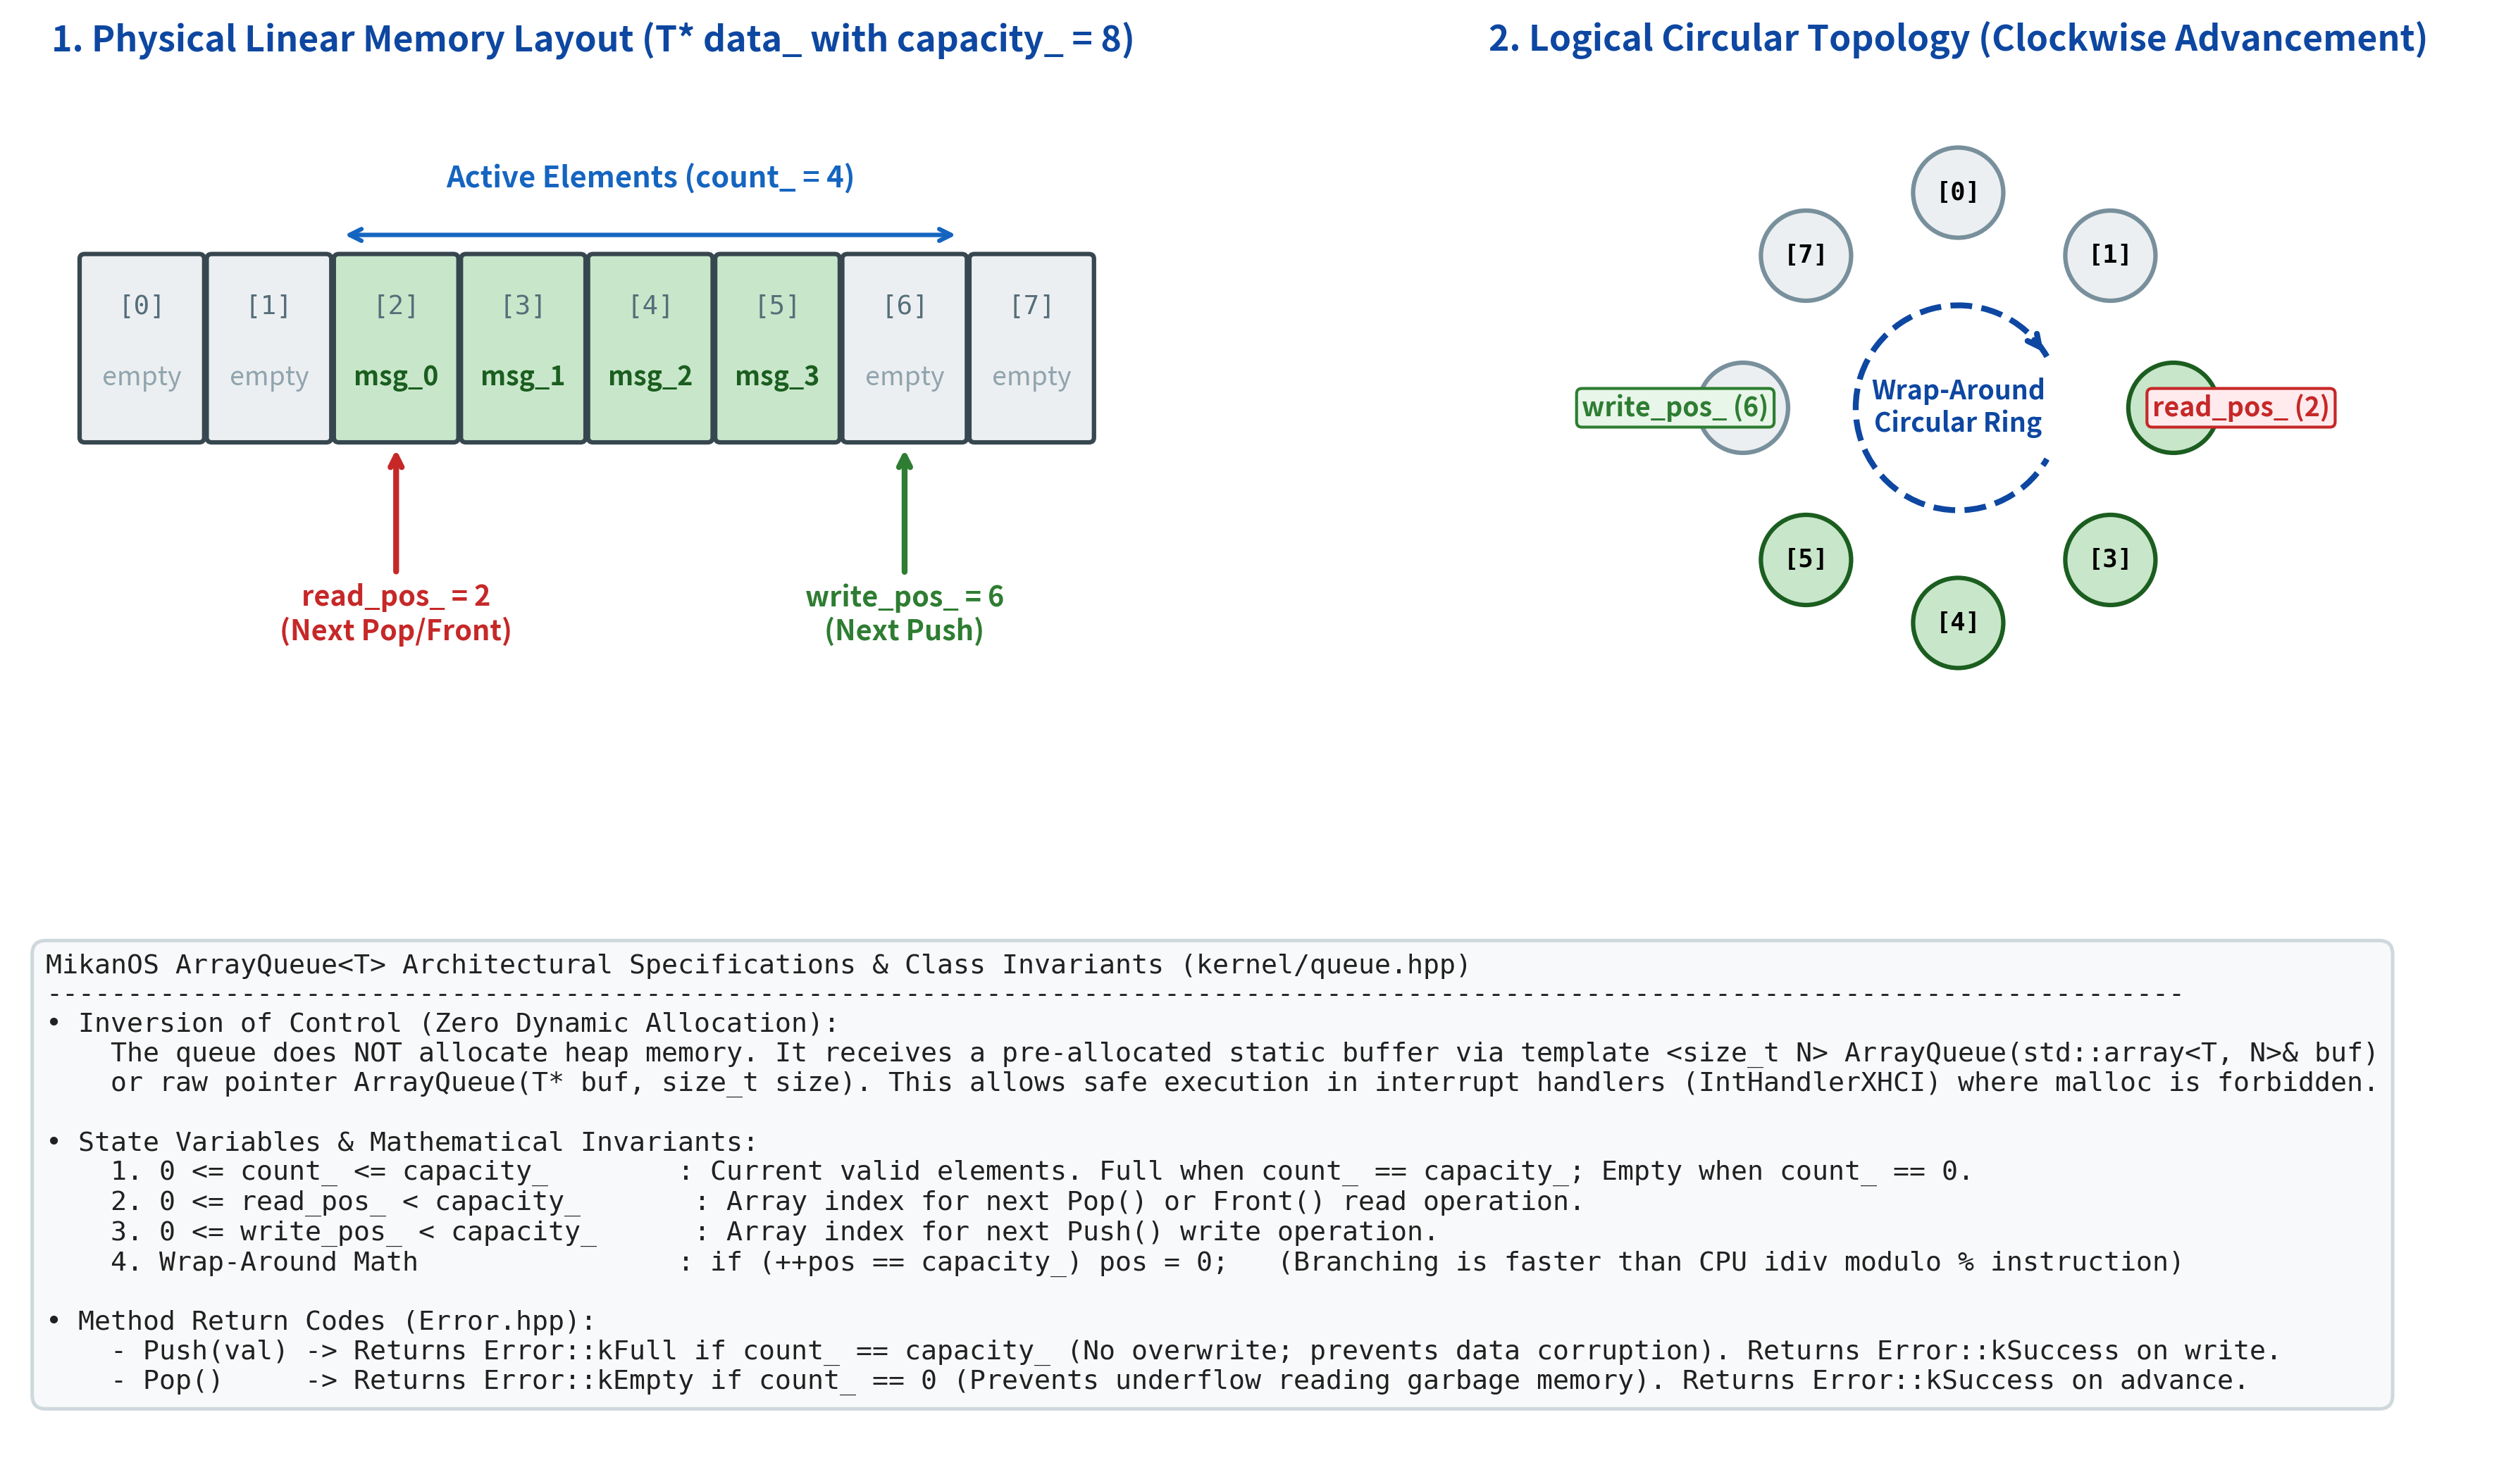

In [2]:
# Figure 7.19 の生成と表示: ArrayQueue<T> リングバッファの物理配列と論理循環トポロジー
import os
from common import plot_arrayqueue_ring_buffer_structure
from IPython.display import Image, display

fig_path = os.path.join(repo_root, "7/result/fig7_19_arrayqueue_ring_buffer_structure_and_pointers.png")
plot_arrayqueue_ring_buffer_structure(fig_path)
display(Image(filename=fig_path))


## 7.9.2 `ArrayQueue<T>` クラステンプレートの完全構造

MikanOS の `kernel/queue.hpp` における `ArrayQueue<T>` の完全なクラス定義を確認しましょう。

```cpp
template <typename T>
class ArrayQueue {
 public:
  template <size_t N>
  ArrayQueue(std::array<T, N>& buf);
  ArrayQueue(T* buf, size_t size);
  Error Push(const T& value);
  Error Pop();
  size_t Count() const;
  size_t Capacity() const;
  const T& Front() const;

 private:
  T* data_;
  size_t read_pos_, write_pos_, count_;
  /*
   * read_pos_ points to an element to be read.
   * write_pos_ points to a blank position.
   * count_ is the number of elements available.
   */
  const size_t capacity_;
};
```

### メンバ変数の役割と不変条件 (Class Invariants)
クラスの健全性を保つため、すべての操作（Push / Pop）の前後で以下の不変条件が常に厳密に成立します：

| メンバ変数 | 型 | 役割 | 成立すべき不変条件 (Invariant) |
|---|---|---|---|
| `data_` | `T*` | 外部から渡された配列の先頭アドレス | `data_ != nullptr`（有効なメモリ領域） |
| `read_pos_` | `size_t` | 次に読み出す（Pop / Front する）先頭要素のインデックス | $0 \le 	ext{read\_pos\_} < 	ext{capacity\_}$ |
| `write_pos_` | `size_t` | 次に書き込む（Push する）末尾の空きスロットインデックス | $0 \le 	ext{write\_pos\_} < 	ext{capacity\_}$ |
| `count_` | `size_t` | 現在キュー内に格納されている有効な要素の総数 | $0 \le 	ext{count\_} \le 	ext{capacity\_}$ |
| `capacity_` | `const size_t` | バッファの最大容量（要素数） | $	ext{capacity\_} > 0$（変更不可定数） |

### 2つのコンストラクタの設計意図
`ArrayQueue` には2つのコンストラクタが定義されています：

```cpp
template <typename T>
template <size_t N>
ArrayQueue<T>::ArrayQueue(std::array<T, N>& buf) : ArrayQueue(buf.data(), N) {}

template <typename T>
ArrayQueue<T>::ArrayQueue(T* buf, size_t size)
  : data_{buf}, read_pos_{0}, write_pos_{0}, count_{0}, capacity_{size}
{}
```

1. **`std::array<T, N>&` を受け取るメンバテンプレートコンストラクタ**:
   - `std::array` は固定長配列を安全に扱うモダンC++のラッパーです。
   - `buf.data()` で生ポインタを取り出し、テンプレート引数 `N` をそのままサイズとして第2のコンストラクタに委譲（*Delegating Constructor*）します。
   - 利用側は `ArrayQueue q(my_array);` と書くだけで、配列サイズを手動で渡す必要がなく、サイズ不一致によるバッファオーバーラン事故をコンパイル時に完全に防ぎます。
2. **生ポインタ `T*` と `size` を受け取るコンストラクタ**:
   - C言語スタイルの生配列や、任意のメモリ領域（MMIOバッファやページフレーム）に対しても柔軟にキューを構築できます。
   - すべてのメンバ変数はメンバ初期化子リスト（*Member Initializer List*）で初期化され、`read_pos_`、`write_pos_`、`count_` はすべて `0` で開始します。


## 7.9.3 Push 操作のステップバイステップ導出

キューの末尾に新しい要素を追加する `Push` 操作の実装です。

```cpp
template <typename T>
Error ArrayQueue<T>::Push(const T& value) {
  if (count_ == capacity_) {
    return MAKE_ERROR(Error::kFull);
  }

  data_[write_pos_] = value;
  ++count_;
  ++write_pos_;
  if (write_pos_ == capacity_) {
    write_pos_ = 0;
  }
  return MAKE_ERROR(Error::kSuccess);
}
```

### 処理の5段階ステップ
1. **満杯（Full）の境界検査**:
   - `count_ == capacity_` をチェックします。すでに容量いっぱいの要素が格納されている場合、これ以上書き込むと未処理の古いデータが上書き破壊（Overwritten）されてしまいます。
   - そのため、即座にエラーコード `MAKE_ERROR(Error::kFull)` を返して処理を中断します。
2. **データの書き込み**:
   - 現在の空きスロット `data_[write_pos_]` に新しい値 `value` をコピー代入します。
3. **有効要素数の加算**:
   - 要素が1つ増えたため、`++count_` を実行します。
4. **書き込み位置の前進と循環（Wrap-Around）**:
   - `++write_pos_` で次のスロットへ進めます。
   - もし `write_pos_ == capacity_` に達したら、配列の終端を超えたことを意味するため、インデックスを配列先頭の `0` にリセットします。
5. **成功復帰**:
   - `MAKE_ERROR(Error::kSuccess)` を返します。

---

### 💡 核心テクニック：なぜ剰余算 `%` ではなく `if` を使うのか？

リングバッファのインデックス循環を教科書的に書くと、多くのプログラミング入門書では以下のように記述されます：

$$	ext{write\_pos\_} = (	ext{write\_pos\_} + 1) \pmod{	ext{capacity\_}};$$

```cpp
// 教科書的な書き方（OSカーネルでは避けるべき実装）
write_pos_ = (write_pos_ + 1) % capacity_;
```

しかし、MikanOS では明示的に以下の条件分岐を採用しています：

```cpp
// MikanOS の高速な実装
++write_pos_;
if (write_pos_ == capacity_) {
  write_pos_ = 0;
}
```

この差は、**x86-64 CPU のマイクロアーキテクチャと機械語命令の実行コスト** に決定的な理由があります。

1. **整数除算命令 (`DIV` / `IDIV`) の重さ**:
   - CPUのハードウェア除算器は、加算器や論理積演算器のように1サイクルで結果を出すことができません。ビットごとに減算とシフトを繰り返す反復型アルゴリズムで動作するため、**20〜45クロックサイクル** の長いレイテンシを消費します。
   - さらに、除算器はCPUパイプライン内で直列化（Serialize）されやすく、後続命令の投機的実行（Out-of-Order Execution）を阻害します。
2. **加算と条件分岐 (`INC` + `CMP` + `JNE` / `CMOV`) の軽さ**:
   - `++write_pos_` はわずか **1クロック** の `INC` 命令です。
   - 終端との比較・リセットは、最新のコンパイラでは条件分岐ジャンプを排して **`CMOV` (Conditional Move)** 命令に最適化されるか、または単純な `JNE` に変換されます。
   - しかも、リングバッファの容量が例えば 32 の場合、インデックスがリセットされるのは「32回に1回」しかありません。つまり、分岐予測器（Branch Predictor）は **$31/32 pprox 96.9\%$** という驚異的な的中率を誇り、パイプラインのストール（Branch Misprediction Penalty）は実質的に皆無です。

> [!TIP]
> 毎秒数千回〜数万回も呼び出される割り込みハンドラやイベントループにおいて、不必要な `DIV` 命令を排除することは、OSの応答性を極限まで高めるための低レイヤにおける鉄則です。


## 7.9.4 Pop 操作と Front 操作の導出

キューの先頭から最古の要素を取り出す `Pop` 操作、および要素を参照する `Front` 操作の実装です。

```cpp
template <typename T>
Error ArrayQueue<T>::Pop() {
  if (count_ == 0) {
    return MAKE_ERROR(Error::kEmpty);
  }

  --count_;
  ++read_pos_;
  if (read_pos_ == capacity_) {
    read_pos_ = 0;
  }
  return MAKE_ERROR(Error::kSuccess);
}

template <typename T>
const T& ArrayQueue<T>::Front() const {
  return data_[read_pos_];
}
```

### Pop 操作の4段階ステップ
1. **空（Empty）の境界検査**:
   - `count_ == 0` をチェックします。キューが空であるにもかかわらず読み進めようとすると、過去に処理済みの古いゴミデータ（Stale Data）を重複処理してしまうことになります。
   - そのため、`MAKE_ERROR(Error::kEmpty)` を返して安全に拒絶します。
2. **有効要素数の減算**:
   - 要素が1つ取り出されるため、`--count_` を実行します。
3. **読み出し位置の前進と循環**:
   - `++read_pos_` で次の要素へ進め、もし `capacity_` に達した場合は `0` へ巻き戻します。
4. **成功復帰**:
   - `MAKE_ERROR(Error::kSuccess)` を返します。

### Front 操作の設計とゼロコピー
- `Front()` は `data_[read_pos_]` への **`const` 参照 (`const T&`)** を返します。
- これにより、サイズが数十バイト〜数百バイトある構造体（`Message` やパケット等）であっても、メモリのコピーコストが一切発生せず、$O(1)$ のゼロオーバーヘッドで先頭データを検査できます。
- 先頭の内容を `Front()` で確認・処理した後に `Pop()` を呼んでバッファから取り除くという、安全で明快な2段階のインターフェースとなっています。


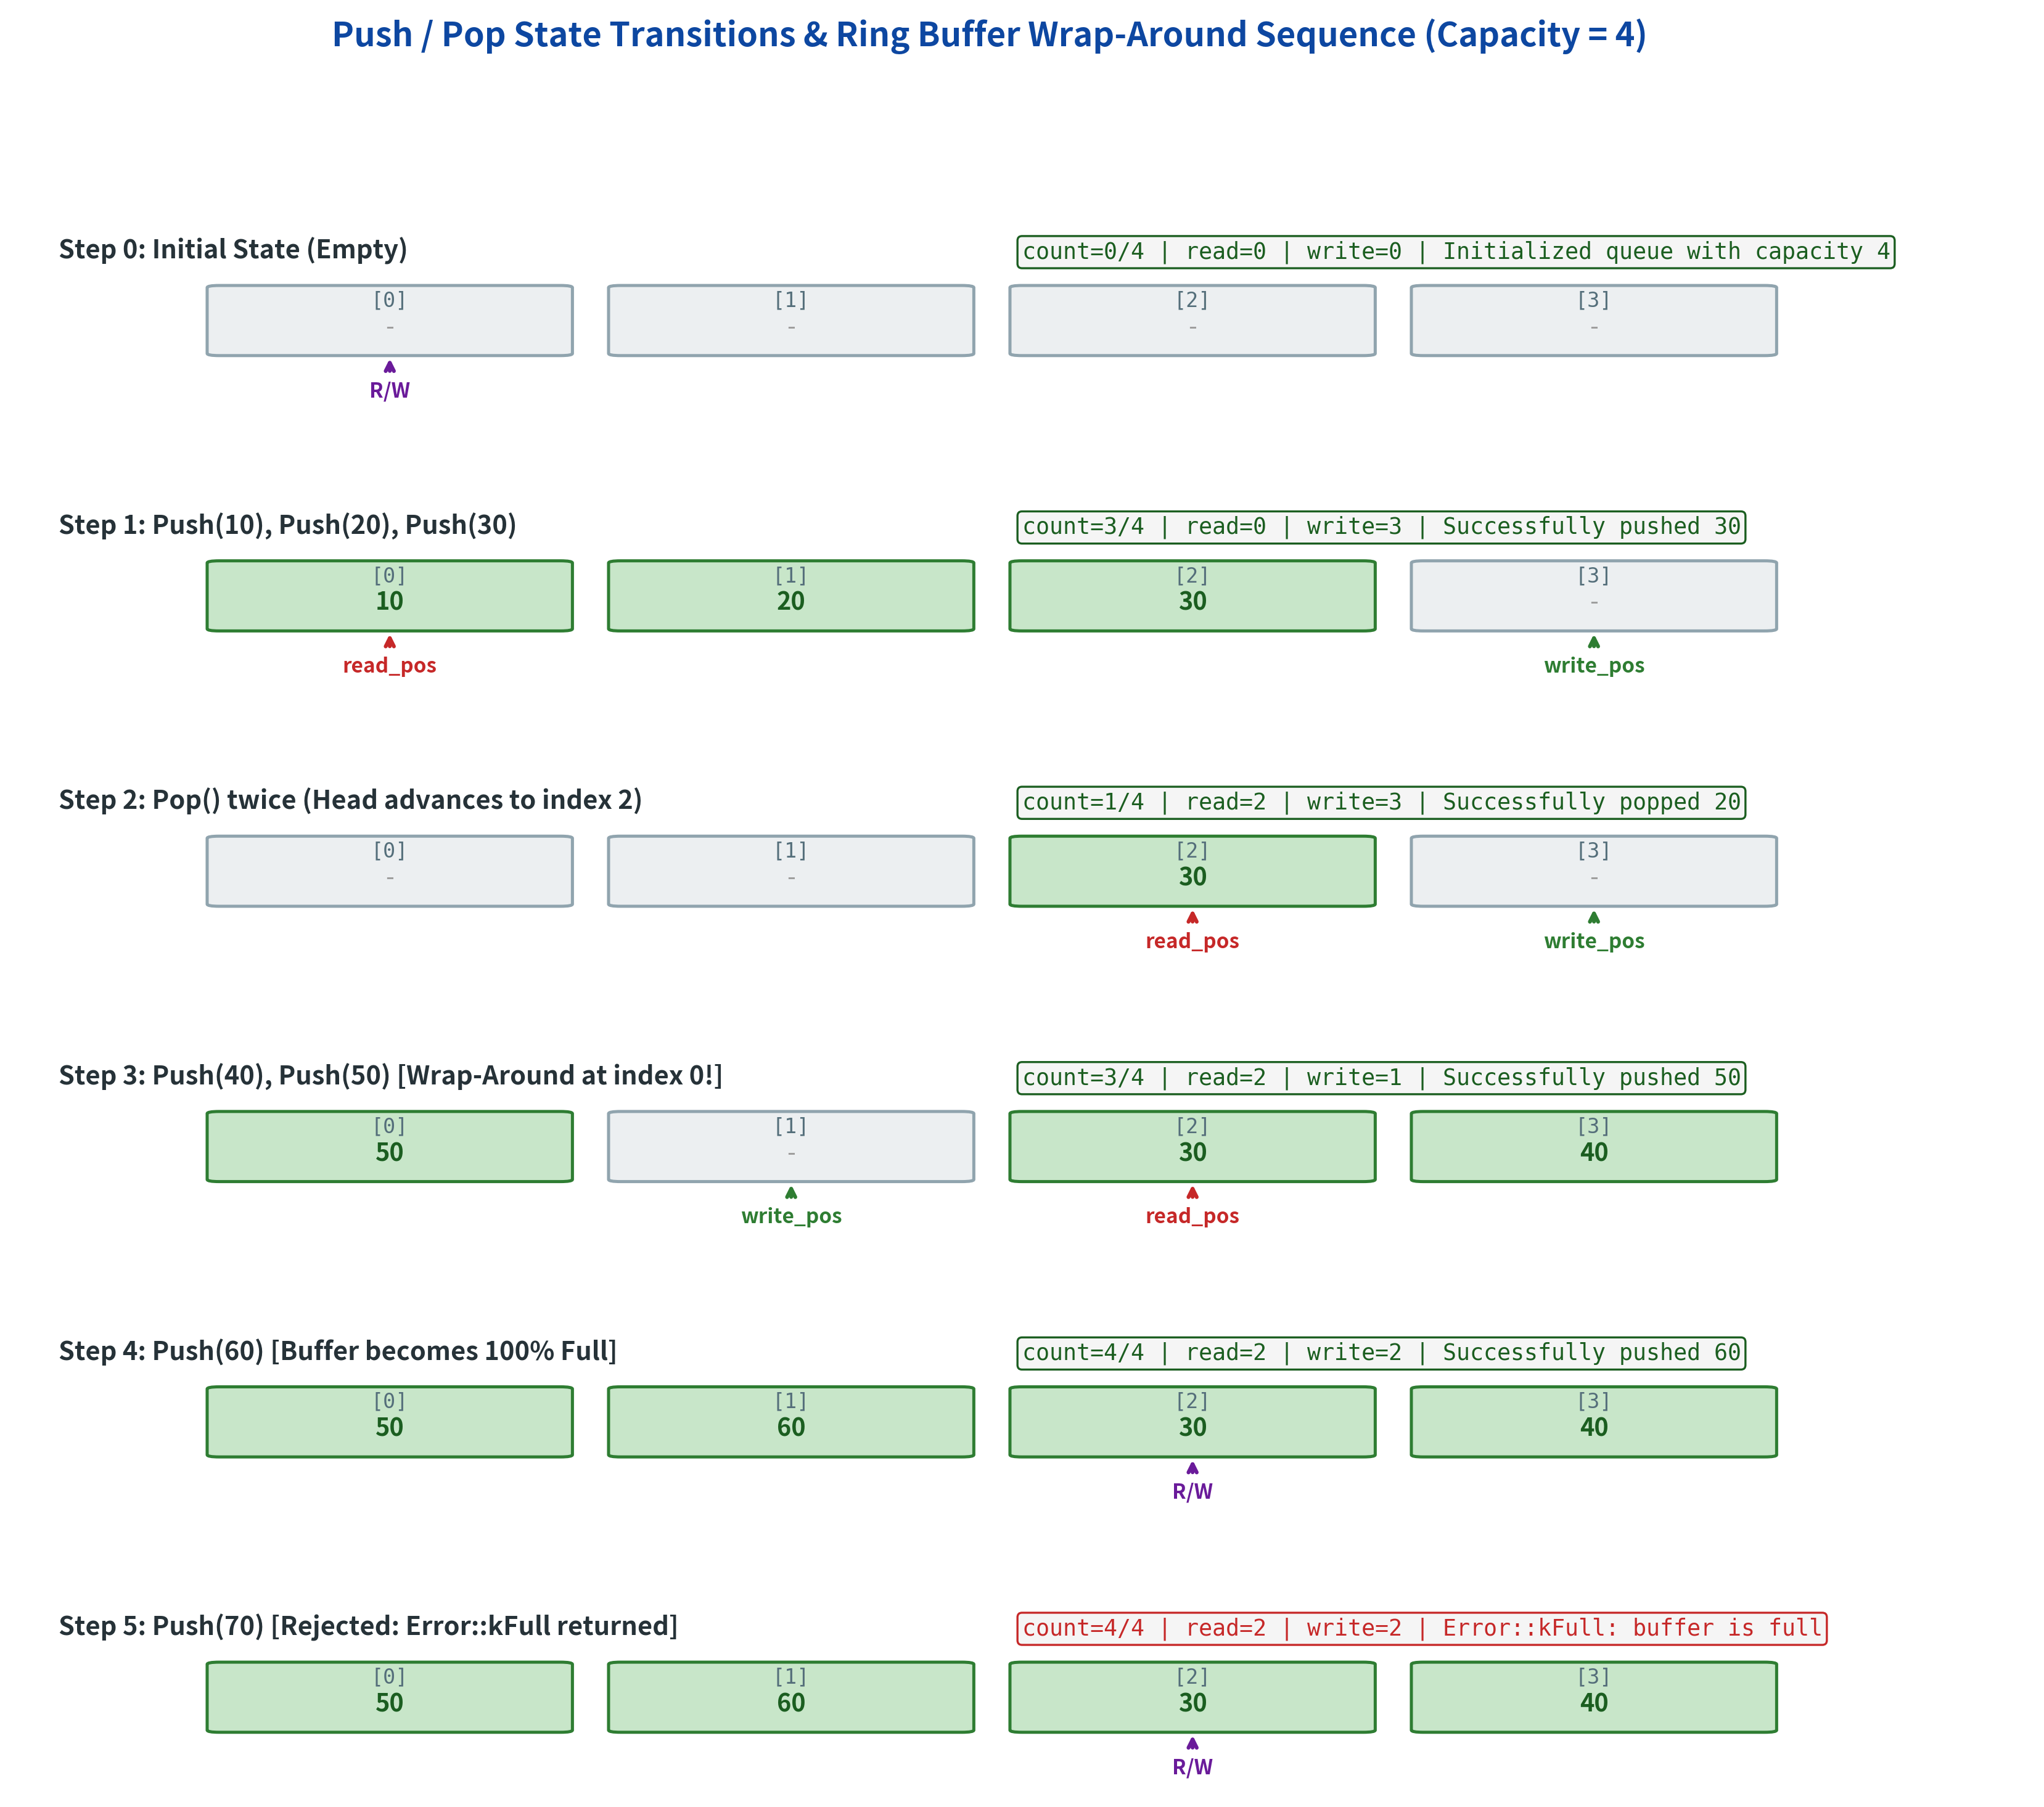

In [3]:
# Figure 7.20 の生成と表示: Push / Pop 操作に伴う状態遷移とポインタ循環シーケンス
import os
from common import plot_push_pop_state_transition_sequence
from IPython.display import Image, display

fig_path = os.path.join(repo_root, "7/result/fig7_20_push_pop_state_transition_sequence.png")
plot_push_pop_state_transition_sequence(fig_path)
display(Image(filename=fig_path))


## 7.9.5 「満杯」と「空」の判別問題：古典的1スロット犠牲 vs MikanOS `count_` 方式

リングバッファを設計する際、計算機科学の歴史上最も有名な落とし穴が **「満杯（Full）と空（Empty）のポインタ一致問題」** です。

### 古典的リングバッファのジレンマ
仮に `count_` という要素数変数を保持せず、`read_pos_`（Head）と `write_pos_`（Tail）の2つのポインタだけでキューを管理しようとしたとします：
- **初期状態（空）**: `read_pos_ == 0`, `write_pos_ == 0` $\implies$ $	ext{read\_pos\_} == 	ext{write\_pos\_}$
- **全スロット書き込み後（満杯）**: バッファサイズを $N$ として $N$ 個書き込むと、`write_pos_` は1周して再び `read_pos_` に追いつく $\implies$ $	ext{read\_pos\_} == 	ext{write\_pos\_}$

つまり、**「空のときも満杯のときも、ポインタ同士が完全に一致してしまう」** ため、ポインタの位置関係だけではバッファが空なのか満杯なのか区別がつかなくなってしまうのです！

```text
[古典的リングバッファのポインタ一致問題]
1. 空の状態 (Empty)     : [   ] [   ] [   ] [   ]
                          ^R,W (read_pos_ == write_pos_ == 0)
                          
2. 満杯の状態 (Full)    : [ A ] [ B ] [ C ] [ D ]
                          ^R,W (write_pos_ が1周して追いついた: read_pos_ == write_pos_ == 0)
                          => ポインタの値だけでは両者を判別できない！
```

---

### アプローチ A：古典的「1スロット犠牲 (One-Slot Waste)」方式
古典的な UNIX カーネルや一部の組込みファームウェアでは、状態変数を1バイトでも減らすために以下の規則を採用していました：
- **空の条件**: `head == tail`
- **満杯の条件**: `(tail + 1) % capacity == head`

この方式では、**「tail の次の位置が head なら満杯とみなす」** というルールにするため、ポインタ同士が完全に重なる前に書き込みを停止させます。
しかし、この方式には致命的な代償があります：
- **容量が必ず 1 個無駄になる（Usable Capacity = $N - 1$）**:
  サイズ 4 の配列を確保しても、実際には 3 個しかデータを入れられません。
  メモリ利用効率は $(N-1)/N$ となり、容量が小さいバッファほど無駄が大きくなります（容量4なら効率 $75\%$、容量2なら効率 $50\%$！）。
- **API利用者の混乱**: 「要素数 32 の配列を渡したのに、なぜか 31 個で `kFull` になる」という直感に反する挙動を招きます。

---

### アプローチ B：MikanOS の「独立した `count_` 変数保持」方式（採用）
MikanOS の `ArrayQueue` では、メモリわずか 8 バイト（64bit `size_t`）の `count_` メンバ変数を明示的に持たせる方式を採用しています。

- **空の判定**: `count_ == 0`
- **満杯の判定**: `count_ == capacity_`

この設計により、以下の絶大なメリットが得られます：
1. **メモリ利用効率 $100\%$**: 確保した $N$ 個のスロットをすべて余すことなくフル活用できる。
2. **`read_pos_ == write_pos_` の曖昧性の完全排除**: ポインタが一致していても、`count_ == 0` なら空、`count_ == capacity_` なら満杯と明快に即時判定できる。
3. **要素数取得 `Count()` の $O(1)$ 化**: ポインタの差分や負数ラップアラウンド計算をすることなく、メンバ変数をそのまま返すだけで瞬時に要素数を取得できる。


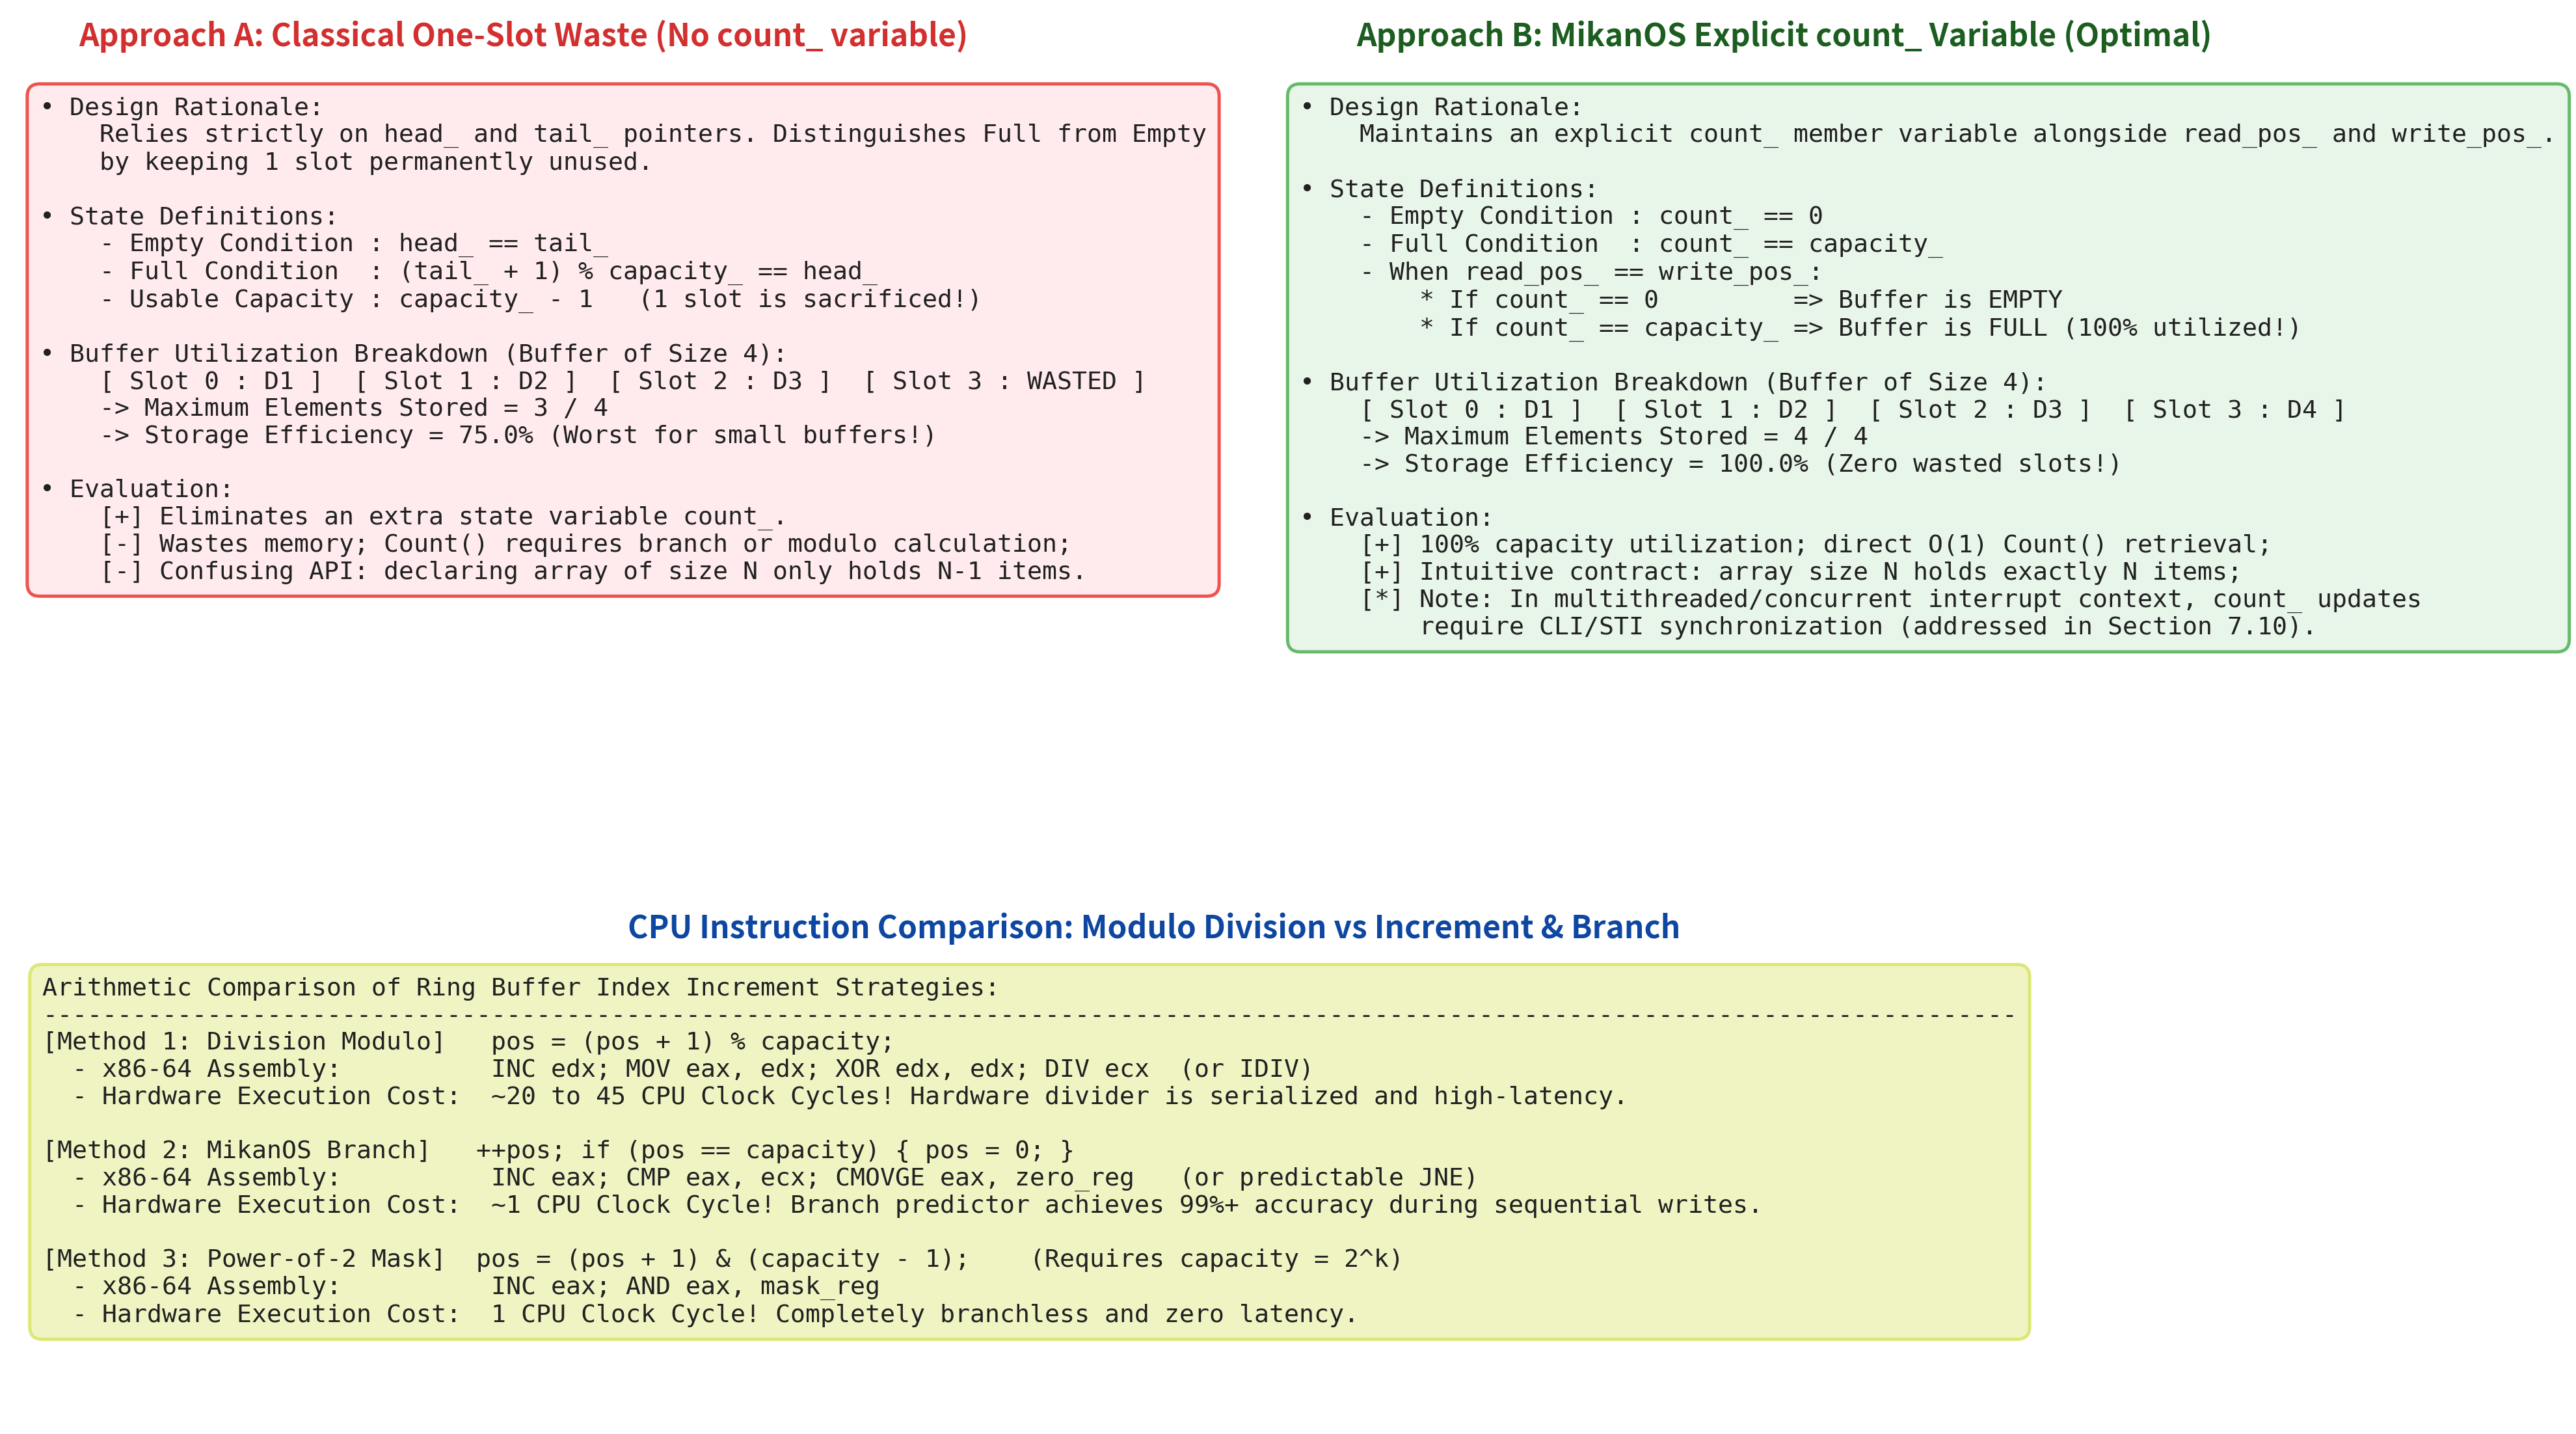

In [4]:
# Figure 7.21 の生成と表示: 境界条件（Full / Empty）判定論理の比較とCPU命令数理
import os
from common import plot_buffer_boundary_and_full_empty_logic
from IPython.display import Image, display

fig_path = os.path.join(repo_root, "7/result/fig7_21_buffer_full_empty_and_wrap_around_logic.png")
plot_buffer_boundary_and_full_empty_logic(fig_path)
display(Image(filename=fig_path))


## 7.9.6 C++ クラステンプレートの分割コンパイル問題とヘッダオンリー設計

MikanOS カーネルのソースコード構成を見ると、ほとんどの機能は宣言をヘッダファイル（`.hpp`）、実装をソースファイル（`.cpp`）に分離して分割コンパイルされています（第5章 5.2節 参照）。
- 例: `console.hpp` と `console.cpp`、`pci.hpp` と `pci.cpp`、`interrupt.hpp` と `interrupt.cpp`

しかし、**`queue.hpp` に対応する `queue.cpp` は存在しません**。クラステンプレートの宣言もメンバ関数の実装も、すべて `queue.hpp` の中に直接書かれています。

なぜテンプレートクラスはヘッダファイル単体にすべてを記述しなければならないのでしょうか？

### コンパイラの実体化機構 (Template Instantiation)
通常の関数やクラスは、型がコンパイル前に完全に決まっています。コンパイラは `console.cpp` を単独でコンパイルし、機械語コードを含む `console.o` を生成できます。

しかし、クラステンプレート `ArrayQueue<T>` は **「型の設計図」** に過ぎず、具体的な型 `T`（例えば `ArrayQueue<Message>` や `ArrayQueue<int>`）が指定されるまで、コンパイラはどのサイズの機械語コードを生成すべきか判断できません。

もし実装を `queue.cpp` に書いてしまうと、以下の問題が発生します：
1. `queue.cpp` を単独コンパイルする際、コンパイラは「このキューがどの型 `T` で使われるのか」を知らないため、コードを一切実体化（生成）できず、空のオブジェクトファイルが作られる。
2. 別のファイル（`main.cpp`）で `ArrayQueue<Message>` を使おうとすると、リンカ（LLD）は「`ArrayQueue<Message>::Push` の実体化された機械語がどのオブジェクトファイルにも存在しない！」という未解決シンボルエラー（*Undefined Reference*）を出してリンクに失敗する。

### 結論：ヘッダオンリーによる ODR 保証
テンプレートのメンバ関数実装をヘッダファイルに記述しておけば、`#include "queue.hpp"` した各翻訳単位（`main.cpp` やテストコード）において、コンパイラはその場で型 `T` を当てはめてインラインに機械語を実体化できます。
C++の単一定義規則 (ODR: *One Definition Rule*) により、複数の翻訳単位で同一のテンプレートが実体化されても、リンカが重複を自動的に統合（COMDAT折りたたみ）してくれるため、シンボル重複エラーも起きません。


## 7.9.7 対話型 C++20 スタンドアロン検証コード (`src/ch07/array_queue_sim.cpp`)

本リポジトリでは、MikanOS の `kernel/queue.hpp` を忠実に再現したスタンドアロン C++20 検証コード [`src/ch07/array_queue_sim.cpp`](../src/ch07/array_queue_sim.cpp) を用意しています。

### 6つの検証シナリオ
1. **`TestBasicOperations`**: 初期状態、Push、Front、Pop による `read_pos_` / `write_pos_` / `count_` の不変条件の推移を検証。
2. **`TestWrapAroundLogic`**: 容量 3 のバッファで Push と Pop を繰り返し、配列終端から先頭 `0` へのインデックス循環と FIFO 順序保持を検証。
3. **`TestBoundaryFullAndEmptyErrors`**: 満杯時の `Push` が `Error::kFull`、空時の `Pop` が `Error::kEmpty` を正確に返し、状態を破壊しないことを検証。
4. **`TestOneSlotWasteComparison`**: MikanOS 方式（利用効率 100%）と古典的 1 スロット犠牲方式（利用効率 75%）のデータ格納数を実測比較。
5. **`TestStructMessageQueue`**: MikanOS の実機イベント構造体 `struct Message`（xHCI イベント、タイマ、キーボード入力）のキューイングと共用体アクセスの健全性を検証。
6. **`TestHighThroughputBenchmark`**: 1000万回の Push/Pop を実行し、動的アロケーションゼロによる極限スループット（数億 Ops/sec）を計測。

以下のセルを実行して、ホスト側 C++20 コンパイラで直接ビルド・実行してみましょう。


In [5]:
# === C++20 スタンドアロン検証コードのコンパイルと実行 ===
import subprocess
import os

cpp_src = os.path.join(repo_root, "src/ch07/array_queue_sim.cpp")
bin_out = os.path.join(repo_root, "build/bin/ch07_array_queue_sim")
if not os.path.exists(bin_out):
    bin_out = os.path.join(repo_root, "src/ch07/array_queue_sim")

print(f"🛠️ C++20 ソースコード: {cpp_src}")
if not os.path.exists(bin_out):
    print(f"🔨 コンパイル実行中: g++ -std=c++20 -O2 -Wall -Wextra -pedantic {cpp_src} -o {bin_out}")
    compile_cmd = [
        "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-pedantic",
        cpp_src, "-o", bin_out
    ]
    res_comp = subprocess.run(compile_cmd, capture_output=True, text=True)
    if res_comp.returncode != 0:
        print("❌ コンパイルエラー:\n", res_comp.stderr)
        raise RuntimeError(f"Compilation failed: {res_comp.stderr}")
    print("✅ コンパイル成功！")

print(f"🚀 スタンドアロン検証バイナリ ({bin_out}) を実行します:\n")
res_run = subprocess.run([bin_out], capture_output=True, text=True)
print(res_run.stdout)
if res_run.stderr:
    print("標準エラー出力:\n", res_run.stderr)
assert res_run.returncode == 0, f"テストバイナリが異常終了しました (code {res_run.returncode})"


🛠️ C++20 ソースコード: /home/student/Documents/GitHub/study-mikanos/src/ch07/array_queue_sim.cpp
🚀 スタンドアロン検証バイナリ (/home/student/Documents/GitHub/study-mikanos/build/bin/ch07_array_queue_sim) を実行します:

 MikanOS Ch 7.9: ArrayQueue Ring Buffer Verification

[Test 1] Basic Push, Pop, Front, and Invariants...
  -> PASSED: Invariants preserved during normal operations.
[Test 2] Pointer Wrap-Around (Circular Buffer Mechanism)...
  -> PASSED: Read and write pointers wrap around accurately.
[Test 3] Boundary Conditions: kFull and kEmpty Errors...
  -> PASSED: Error codes kFull and kEmpty returned without corruption.
[Test 4] Comparison: MikanOS count_-based vs One-Slot Waste...
  MikanOS ArrayQueue pushed: 4 elements (Utilization: 100.0%)
  OneSlotWasteQueue pushed:  3 elements (Utilization: 75%)
  -> PASSED: MikanOS design achieves full 100% capacity utilization.
[Test 5] Complex Struct Payload (os::Message)...
  -> PASSED: Event messages correctly enqueued and dequeued.
[Test 6] High-Throughput Perf

## 7.9.8 Python シミュレータ (`ArrayQueueSim`) による対話的動作追跡

C++ のコアロジックを直感的に探究できるよう、Python 側でも `common.ArrayQueueSim` を提供しています。
以下のセルでは、容量 4 のリングバッファに対して Push と Pop を順次実行し、内部バッファの各スロットの状態とポインタの変化を1行ずつテーブル形式で追跡します。


In [6]:
# === Python シミュレータによるリングバッファ状態追跡 ===
from common import ArrayQueueSim

# 容量 4 のキューを作成
q_sim = ArrayQueueSim(capacity=4)

print(f"{'Step':<5} | {'Action':<12} | {'Success':<8} | {'Read':<5} | {'Write':<5} | {'Count':<5} | {'Buffer State':<22} | {'Description'}")
print("-" * 105)

operations = [
    ("push", 101),
    ("push", 102),
    ("push", 103),
    ("pop", None),
    ("pop", None),
    ("push", 104),
    ("push", 105),
    ("push", 106),  # 満杯になる
    ("push", 999),  # 満杯のため失敗するはず
    ("pop", None),
    ("pop", None),
    ("pop", None),
    ("pop", None),  # すべて取り出して空になる
    ("pop", None),  # 空のため失敗するはず
]

for op, val in operations:
    if op == "push":
        q_sim.push(val)
    else:
        q_sim.pop()

for snap in q_sim.history:
    buf_display = str([x if x is not None else "-" for x in snap.buffer])
    succ_str = "OK" if snap.success else "FAILED"
    print(f"{snap.step:<5} | {snap.action:<12} | {succ_str:<8} | {snap.read_pos:<5} | {snap.write_pos:<5} | {snap.count:<5} | {buf_display:<22} | {snap.description}")


Step  | Action       | Success  | Read  | Write | Count | Buffer State           | Description
---------------------------------------------------------------------------------------------------------
0     | Init         | OK       | 0     | 0     | 0     | ['-', '-', '-', '-']   | Initialized queue with capacity 4
1     | Push(101)    | OK       | 0     | 1     | 1     | [101, '-', '-', '-']   | Successfully pushed 101
2     | Push(102)    | OK       | 0     | 2     | 2     | [101, 102, '-', '-']   | Successfully pushed 102
3     | Push(103)    | OK       | 0     | 3     | 3     | [101, 102, 103, '-']   | Successfully pushed 103
4     | Pop()        | OK       | 1     | 3     | 2     | ['-', 102, 103, '-']   | Successfully popped 101
5     | Pop()        | OK       | 2     | 3     | 1     | ['-', '-', 103, '-']   | Successfully popped 102
6     | Push(104)    | OK       | 2     | 0     | 2     | ['-', '-', 103, 104]   | Successfully pushed 104
7     | Push(105)    | OK       | 2     

## 7.9.9 理解度セルフチェック演習問題

本節で学んだリングバッファの設計思想と実装技術について、理解度を確認しましょう。各問題の「解答・解説」をクリックすると詳細な解説が展開されます。

---

### 問題 1: 満杯と空のポインタ一致
MikanOS の `ArrayQueue` において、`read_pos_ == write_pos_` となる状況は具体的にどのような場合か？ また、その状況においてキューが「空」であるか「満杯」であるかをどのように判別しているか答えよ。

<details>
<summary>▶ 解答・解説を展開</summary>

**解答**:
1. `read_pos_ == write_pos_` となる状況は、**「キューが完全に空（要素数 0）のとき」** および **「キューが完全に満杯（要素数 `capacity_`）のとき」** の2つのケースである。
2. MikanOS では、メンバ変数 **`count_`** を保持しているため、ポインタが一致していても：
   - `count_ == 0` であれば **空（Empty）**
   - `count_ == capacity_` であれば **満杯（Full）**
   と明確に判別できる。

**解説**:
古典的なリングバッファでは `count_` 変数を持たないため、この両者を区別するために1スロットを常に空けておく「1スロット犠牲方式」を取る必要がありました。MikanOS では `count_` 変数を導入することで、全スロットを100%無駄なく活用しています。
</details>

---

### 問題 2: インデックス循環の計算コスト
リングバッファのインデックス更新において、なぜ `pos = (pos + 1) % capacity_;` ではなく、`++pos; if (pos == capacity_) pos = 0;` という条件分岐による実装が推奨されるのか、ハードウェアアーキテクチャの観点から説明せよ。

<details>
<summary>▶ 解答・解説を展開</summary>

**解答**:
x86-64 CPU において、剰余算命令（`DIV` / `IDIV`）は直列化されたハードウェア除算器を使用するため **20〜45クロックサイクル** もの長いレイテンシを消費する。
一方、加算と条件分岐（`INC` + `CMP` / `CMOV`）は **1クロックサイクル** で実行できる上、インデックスがリセットされるのは `capacity_` 回に1回しかないため、現代のCPUの分岐予測器がほぼ100%ヒットしてパイプラインのストールが発生しないためである。

**解説**:
割り込みハンドラなどの高頻度・超低遅延が要求されるコードパスでは、高価な除算命令を避け、単純な加算と予測しやすい条件分岐に置き換えることが性能向上の鍵となります。
</details>

---

### 問題 3: テンプレートクラスのヘッダオンリー化
なぜ `ArrayQueue<T>` のメンバ関数（`Push` や `Pop`）の実装は `queue.cpp` に分けず、すべて `queue.hpp` の中に記述しなければならないのか、C++ コンパイラとリンカの動作原理に基づいて説明せよ。

<details>
<summary>▶ 解答・解説を展開</summary>

**解答**:
クラステンプレートは型引数 `T` が定まるまでコンパイラが機械語コードを生成（実体化: Instantiation）できない。もし実装を `queue.cpp` に分離すると、そのファイルをコンパイルする時点では `T` に何が入るか不明なため機械語が生成されない。
その結果、別のソースファイル（`main.cpp` 等）で `ArrayQueue<Message>` を呼び出した際に、リンカが実体化されたコードを見つけられず、未解決シンボルエラー（*Undefined Reference*）が発生するためである。

**解説**:
ヘッダファイルに実装を記述しておけば、`#include "queue.hpp"` した各翻訳単位において、具体的な型 `T` に基づいてコンパイラがその場でコードを生成できます。重複した実体化コードはリンカによって自動的に1つに統合されます。
</details>


## 7.9.10 まとめと次節（7.10 キューを使った割り込み高速化）への展望

本節では、MikanOS のイベント処理の要である固定長リングバッファ **`ArrayQueue<T>`** の完全なアーキテクチャと実装を学習しました。

### 本節の要点まとめ
1. **動的メモリ非依存の設計**: 外部から静的配列を受け取る依存性注入モデルにより、ヒープマネージャ不在のベアメタル環境や割り込みコンテキストでも安全に動作する。
2. **メモリ利用効率 $100\%$ の達成**: 独立した `count_` 変数により、古典的「1スロット犠牲方式」の無駄を排除し、全スロットを完全活用。
3. **CPUに最適化されたインデックス循環**: 重い `DIV` 命令を回避し、`INC` と予測性の極めて高い条件分岐により 1 クロック級の高速更新を実現。
4. **ヘッダオンリーテンプレート設計**: 型安全性とゼロオーバーヘッド、そして C++ テンプレートの実体化規則に適合したクラス構造。

---

### ⚠️ 次節 7.10 への布石：立ち塞がる「競合状態（Race Condition）」の壁

`ArrayQueue` の実装が完成したことで、我々は割り込みハンドラ（Top Half）からメインループ（Bottom Half）へイベントを安全・高速に受け渡す道具を手に入れました。

しかし、ここで **マルチタスク・並行処理における最も恐ろしいバグ** が姿を現します：

> **「メインループがキューから `Pop()` している真っ最中に、マウス割り込みが発生して `Push()` が割り込んだら何が起きるか？」**

- メインループが `count_` を減算（`--count_`）しようとレジスタに読み込んだ瞬間、割り込みハンドラが `Push` して `count_` を加算（`++count_`）したら？
- **`count_` の値が破壊され、空なのに満杯と誤認されたり、バッファオーバーランが発生する！**

このデータ競合（*Race Condition*）を防ぐため、OSカーネルはCPUの割り込みフラグを操作する特権命令 **`CLI` (Clear Interrupt Flag)** と **`STI` (Set Interrupt Flag)**、そしてプロセッサを休止させる **`HLT` 命令** を駆使した厳密な同期制御を行う必要があります。

次節 **「7.10 キューを使った割り込み高速化」** では、このクリティカルセクションの保護と、アイドル時のCPU消費電力をゼロにする `STI; HLT` イディオムの数理と実装に挑みます！
